<a href="https://colab.research.google.com/github/mahemahendra7777-oss/Edu-Pro-Instructor-Evaluation/blob/main/edu_pro_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [42]:
import pandas as pd
from google.colab import files

print("Please upload your CSV files:")
uploaded = files.upload()

Please upload your CSV files:


Saving EduPro Online Platform.xlsx to EduPro Online Platform (4).xlsx


In [43]:
# Load datasets dynamically from the uploaded Excel file:
import os

excel_file = 'EduPro Online Platform.xlsx'
if not os.path.exists(excel_file):
    # fallback to the most recent uploaded duplicate if the original name doesn't exist
    excel_file = 'EduPro Online Platform (3).xlsx'

# Read each sheet from the Excel file
Teachers = pd.read_excel(excel_file, sheet_name='Teachers')
Courses = pd.read_excel(excel_file, sheet_name='Courses')
Transactions = pd.read_excel(excel_file, sheet_name='Transactions')
users = pd.read_excel(excel_file, sheet_name='Users')

# Standardize variable names
teachers = Teachers
courses = Courses
transactions = Transactions

print("\n✅ Files uploaded and loaded successfully from Excel sheets!")
print(f" - Teachers: {teachers.shape}")
print(f" - Courses: {courses.shape}")
print(f" - Transactions: {transactions.shape}")
print(f" - Users: {users.shape}")


✅ Files uploaded and loaded successfully from Excel sheets!
 - Teachers: (60, 7)
 - Courses: (60, 8)
 - Transactions: (10000, 7)
 - Users: (3000, 5)


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [45]:
# Set style for visualizations
sns.set_theme(style="whitegrid")

print("="*60)
print("EDU_PRO DATA ANALYSIS & INSIGHTS GENERATOR")
print("="*60)

EDU_PRO DATA ANALYSIS & INSIGHTS GENERATOR


In [46]:
# 1. Merge the datasets
df = transactions.merge(teachers, on='TeacherID', suffixes=('', '_teacher'))
df = df.merge(courses, on='CourseID', suffixes=('', '_course'))

print("Merged Dataset Shape:", df.shape)


Merged Dataset Shape: (10000, 20)


In [47]:
# 2. Compute key metrics
print("\n--- Summary Statistics ---")
print(f"Average Teacher Rating: {teachers['TeacherRating'].mean():.2f}")
print(f"Average Course Rating: {courses['CourseRating'].mean():.2f}")
print(f"Total Transactions: {len(transactions):,}")



--- Summary Statistics ---
Average Teacher Rating: 3.12
Average Course Rating: 3.10
Total Transactions: 10,000


In [48]:
# Category performance breakdown
category_summary = df.groupby('CourseCategory').agg(
    Enrollments=('TransactionID', 'count'),
    AvgCourseRating=('CourseRating', 'mean'),
    AvgTeacherRating=('TeacherRating', 'mean')
).reset_index().sort_values(by='Enrollments', ascending=False)

print("\n--- Category Performance Summary ---")
print(category_summary.to_string(index=False))


--- Category Performance Summary ---
         CourseCategory  Enrollments  AvgCourseRating  AvgTeacherRating
           Data Science          916         3.335207          4.130928
                Finance          864         3.044016          4.275764
        Web Development          844         2.880320          4.067263
               Business          833         2.693685          3.899556
     Project Management          829         3.123136          4.113643
Artificial Intelligence          829         3.122497          4.008565
                 Design          827         3.179093          4.001657
          Cybersecurity          819         2.975104          3.847766
       Machine Learning          819         2.712320          4.285360
      Digital Marketing          808         3.682574          4.119369
            Programming          806         3.053945          4.125819
              Marketing          806         3.686253          4.169764


In [49]:
# 3. Generate Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


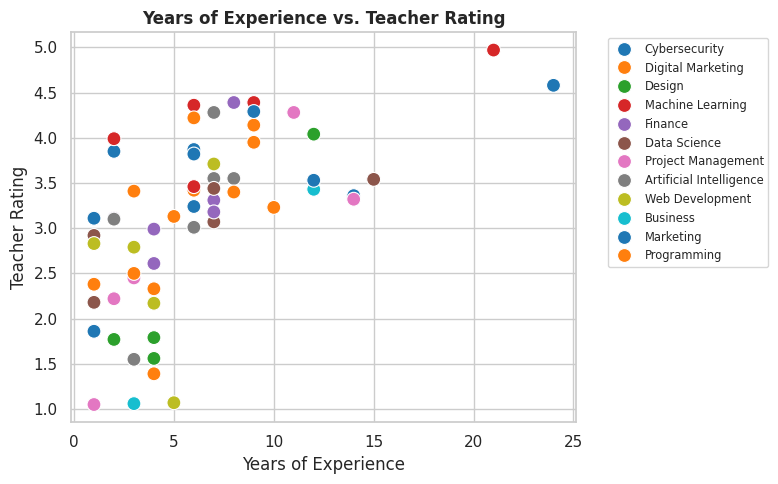

In [50]:
# Plot 1: Experience vs Teacher Rating
plt.figure(figsize=(8, 5))
sns.scatterplot(data=teachers, x='YearsOfExperience', y='TeacherRating', hue='Expertise', s=100, palette='tab10')
plt.title('Years of Experience vs. Teacher Rating', fontsize=12, fontweight='bold')
plt.xlabel('Years of Experience')
plt.ylabel('Teacher Rating')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='x-small')
plt.tight_layout()
plt.savefig('experience_vs_rating.png', dpi=300)
plt.show()

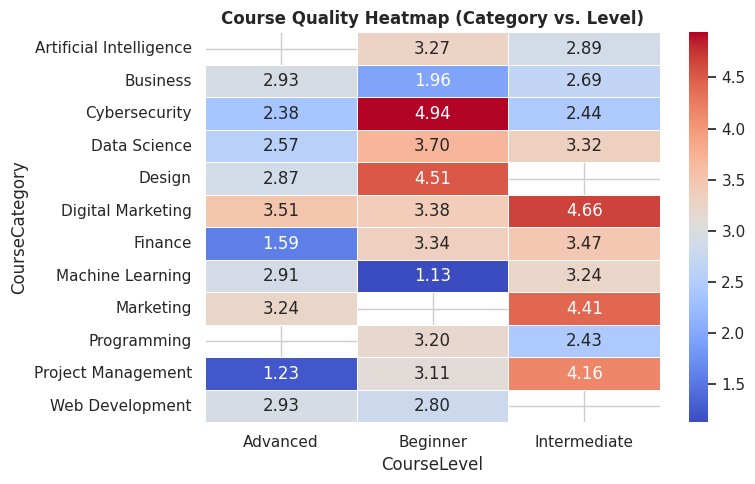


✅ Analysis complete and plots saved successfully!


In [51]:
# Plot 2: Course Quality Heatmap
pivot_table = df.pivot_table(index='CourseCategory', columns='CourseLevel', values='CourseRating', aggfunc='mean')
plt.figure(figsize=(8, 5))
sns.heatmap(pivot_table, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Course Quality Heatmap (Category vs. Level)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('course_quality_heatmap.png', dpi=300)
plt.show()

print("\n✅ Analysis complete and plots saved successfully!")